In [1]:
import numpy as np
import matplotlib.pyplot as plt
from tqdm import tqdm
from estimator_functions import *

plt.rcParams.update({
    "text.usetex": True,
    "font.family": "serif",
    "text.latex.preamble": r"\usepackage{lmodern}"
}) 

In [2]:
def D_to_noise_std(D):
    """
    Convert diffusion coefficient D to per-step noise_std used in Euler-Maruyama.

    Parameters:
        D (float): Diffusion coefficient in the SDE (dX = f dt + sqrt(2D) dW)

    Returns:
        noise_std (float): Standard deviation to use in X[t] = X[t-1] + f*dt + noise_std*sqrt(dt)*randn()
    """
    return np.sqrt(2 * D)


def noise_std_to_D(noise_std, dim=2):
    """
    Convert per-step noise_std back to diffusion coefficient D.

    Parameters:
        noise_std (float): Standard deviation used in Euler-Maruyama step

    Returns:
        D (float): Diffusion coefficient in the SDE
    """
    return noise_std**2 / dim


def noise_strength_to_D(noise_strength, dt, dim=1, sde_convention="sqrt2D"):
    """
    Convert tracker noise_strength to diffusion coefficient D.

    Parameters
    ----------
    noise_strength : float
        Exponential moving average of squared noise increments (⟨et^2⟩).
    dt : float
        Simulation time step.
    dim : int, default=1
        Dimension of the system (length of et).
    sde_convention : str, default="sqrt2D"
        - "sqrt2D": et ~ sqrt(2 D dt) * xi  (standard SDE definition)
        - "sqrtD":  et ~ sqrt(D dt) * xi    (common simulation convention without factor 2)

    Returns
    -------
    D : float
        Estimated per-component diffusion coefficient.
    """
    if sde_convention == "sqrt2D":
        return noise_strength / (2 * dt * dim)
    elif sde_convention == "sqrtD":
        return noise_strength / (dt * dim)
    else:
        raise ValueError("sde_convention must be 'sqrt2D' or 'sqrtD'")



# Test on double well

In [3]:
# Double well system 
def potential(X, Y):
    return (X**2 - 1)**2 + 2*Y**2

def drift_func(t, x):
    dx0 = -1 * x[0] * (x[0]**2 - 1)
    dx1 = -4 * x[1]
    return np.array([dx0, dx1])

np.random.seed(0)
T = 500
dt = 0.01
dim = 2
X = np.zeros((T, dim))
X[0] = np.array([0.05, 0.05])  # start near saddle
D = 0.01
noise_std = D_to_noise_std(D)

for t in range(1, T):
    dx = drift_func(t, X[t-1])
    X[t] = X[t-1] + dx*dt + noise_std*np.random.randn(dim)

In [4]:
tracker = ExponentialCovarianceTracker(dim, gamma=0.999, store_history=True)
#tracker = OnlineCovarianceTracker(dim, store_history=True)

# --- Compare inferred A to linearization at saddle ---
A_linearized = np.array([[1, 0], [0, -4]])
#A_linearized = np.eye(2) + A_linearized * dt
A_stable =  np.array([[-2, 0], [0, -4]]) #* dt +np.eye(2) +

In [ ]:
# Parameters
n_trajs = 256
T = 100       # steps per trajectory
dt = 0.01
dim = 2
D = 0.01
noise_std = D_to_noise_std(D)

# Multiple initial positions
seed_init = 20
np.random.seed(seed_init)
initial_positions = [np.random.uniform(-.1, .1, size=(dim,)) for _ in range(n_trajs)]

# Initialize tracker
eta_e = 0.01
tracking_method = "online"
if tracking_method == "offline":
    tracker = ExponentialCovarianceTracker(dim, gamma=0.999, eta_e=eta_e, store_history=True)
elif tracking_method == "online":
    eta_M = 0.0005
    eta_w = 0.0005
    eta_mean = 0.001
    tracker = OnlineCovarianceTracker(dim, eta_mean=eta_mean, eta_M=eta_M, eta_w=eta_w, eta_e=eta_e, n_iter_lu=1, store_history=True)
else: 
    raise ValueError("tracking_method must be 'offline' or 'online'")

all_X_uncontrolled = []
seed_sim = seed_init
np.random.seed(seed_sim)
for x0 in initial_positions:
    # Initialize trajectory
    X = np.zeros((T, dim))
    X[0] = x0

    # Simulate trajectory
    for t in range(1, T):
        dx = drift_func(t, X[t-1])
        X[t] = X[t-1] + dx*dt + noise_std*np.random.randn(dim)*np.sqrt(dt)

        # Step tracker
        tracker.step(X[t], X[t-1])

    #tracker.reset_trajectory()
    all_X_uncontrolled.append(X)

In [49]:
A_smooth = np.mean(tracker.A_history[-500:], axis=0)  # average last 500 steps
A_est = (A_smooth - np.eye(tracker.dim)) / dt
Lambda_est, Q_mat_est = np.linalg.eig(A_est)
Lambda_est, A_est

(array([ 0.7689596 , -4.01814256]),
 array([[ 0.77168366, -0.08923034],
        [ 0.14622611, -4.02086662]]))

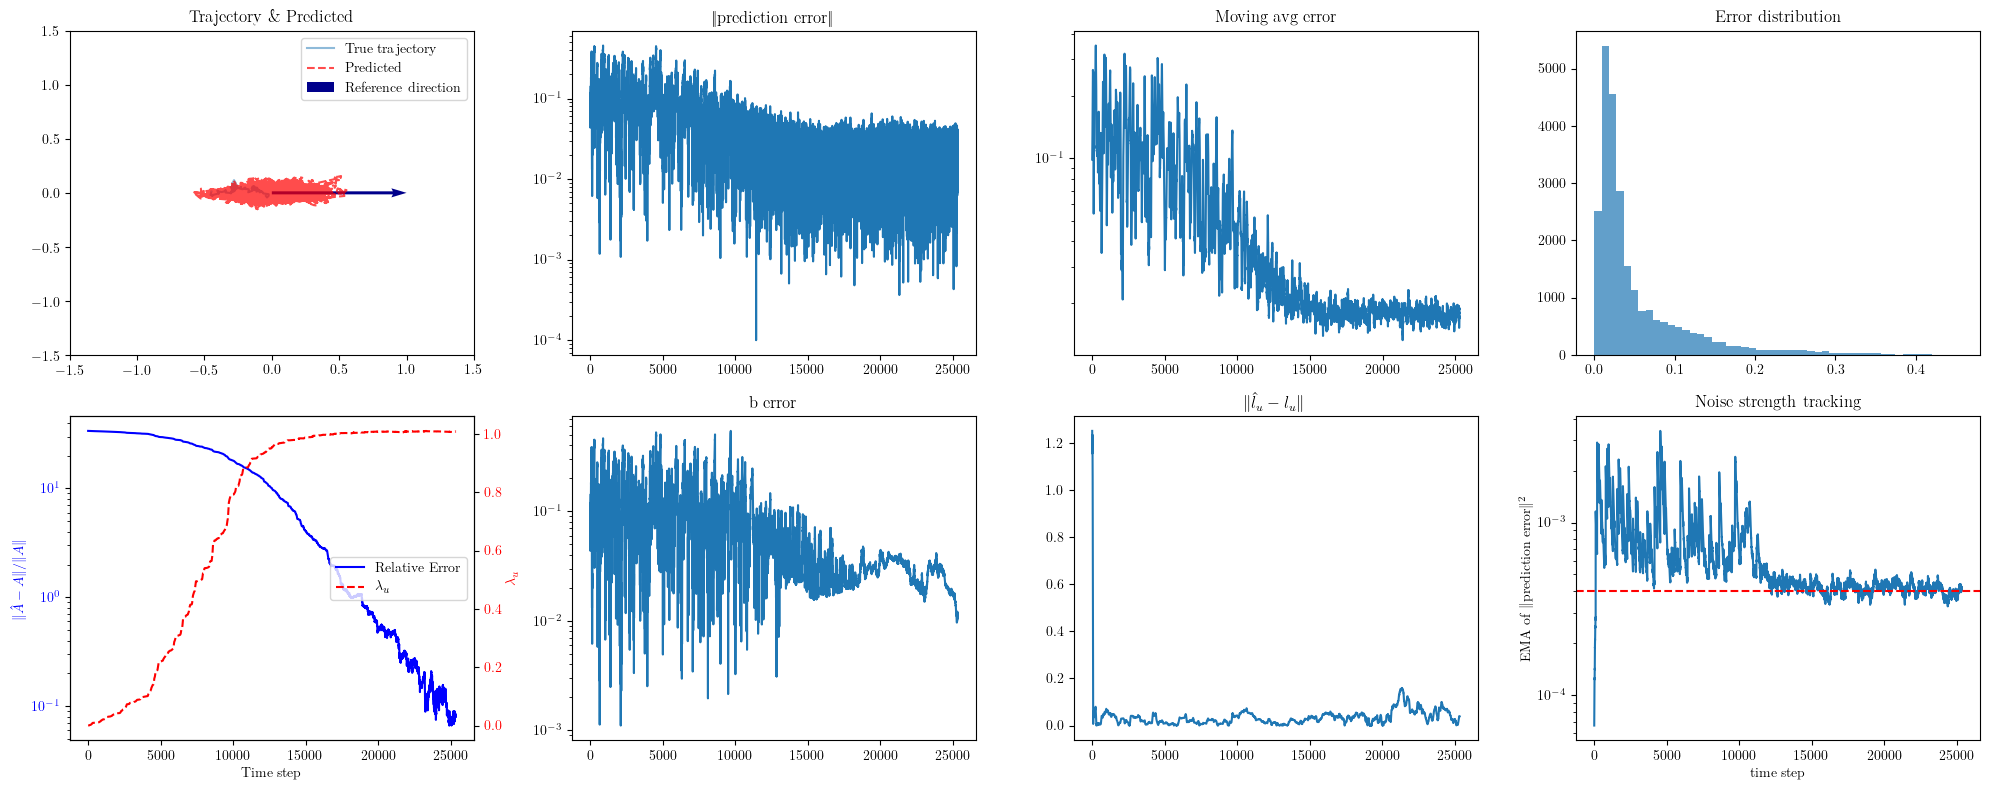

In [50]:
tracker.pred_history = np.array(tracker.pred_history)
tracker.b_history = np.array(tracker.b_history)
tracker.lu_history = np.array(tracker.lu_history)
tracker.noise_history = np.array(tracker.noise_history)

l_true = -np.array([1, 0])

plt.figure(figsize=(20,8))

# 1. Phase portrait with predictions vs true
plt.subplot(2,4,1)
plt.plot(X[:,0], X[:,1], alpha=0.5, label="True trajectory")
plt.plot(tracker.pred_history[:,0], tracker.pred_history[:,1], 'r--', alpha=0.7, label="Predicted")
plt.quiver(0, 0, 1, 0, color='darkblue', scale=3, label="Reference direction")
plt.legend(); plt.title("Trajectory \& Predicted")
plt.xlim([-1.5,1.5])
plt.ylim([-1.5,1.5])

# 2. Prediction error norm
plt.subplot(2,4,2)
plt.plot(tracker.pred_error_history)
plt.yscale("log")
plt.title("‖prediction error‖")

# 3. Moving average error
plt.subplot(2,4,3)
window = 50
mov_avg = np.convolve(tracker.pred_error_history, np.ones(window)/window, mode='valid')
plt.plot(mov_avg)
plt.yscale("log")
plt.title("Moving avg error")

# 4. Error histogram
plt.subplot(2,4,4)
plt.hist(tracker.pred_error_history, bins=50, alpha=0.7)
plt.title("Error distribution")

# 5. Relative error in continuous-time linearization
plt.subplot(2,4,5)
rel_error = np.array([
    np.linalg.norm((A - np.eye(2))/dt - A_linearized, 'fro') / np.linalg.norm(A_linearized, 'fro')
    for A in tracker.A_history
])
fig = plt.gcf()  # get current figure
ax1 = plt.gca()  # get current axis (subplot 5)

# Plot relative error
ax1.plot(rel_error, color='blue', label="Relative Error")
ax1.set_yscale("log")
#ax1.set_title(r"$\|\hat{A} - A\| / \|A\|$")
ax1.set_xlabel("Time step")
ax1.set_ylabel("$\|\hat{A} - A\| / \|A\|$", color='blue')
ax1.tick_params(axis='y', labelcolor='blue')

# Plot lambda on second y-axis
ax2 = ax1.twinx()
ax2.plot(tracker.lambda_history, color='red', linestyle='--', label=r"$\lambda_u$")
ax2.set_ylabel("$\lambda_u$", color='red')
ax2.tick_params(axis='y', labelcolor='red')

# Optional: add combined legend
lines, labels = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines + lines2, labels + labels2, loc='right')

#
tracker.b_history = np.array(tracker.b_history)
plt.subplot(2,4,6)
#plt.plot(tracker.b_history[:,0], tracker.b_history[:,1])
plt.plot(np.linalg.norm(tracker.b_history, axis=1))
#plt.xlim([-1.5, 1.5])
#plt.ylim([-1.5, 1.5])
plt.yscale("log")
plt.title("b error")


plt.subplot(2,4,7)
errors = [np.min([np.linalg.norm(l - l_true),np.linalg.norm(l + l_true)]) for l in tracker.lu_history]
plt.plot(errors)
plt.title("$\|\hat{l}_u - l_u\|$") #min of both norms

plt.subplot(2,4,8)
plt.plot(tracker.noise_history)
true_noise_strength = dim * noise_std**2  * dt
plt.axhline(true_noise_strength, color='r', linestyle='--', label="True noise strength")
plt.yscale("log")
plt.title("Noise strength tracking")
plt.xlabel("time step")
plt.ylabel("EMA of $\|$prediction error$\|^2$")

plt.tight_layout()
if tracking_method == "offline":
    plt.savefig(f"estimation_results_{tracking_method}_etae{eta_e}_rs{seed_init}.pdf", dpi=300)
elif tracking_method == "online":
    plt.savefig(f"estimation_results_{tracking_method}_etam{eta_M}_etaw{eta_w}_etamean{eta_mean}_etae{eta_e}_rs{seed_init}.pdf", dpi=300)
plt.show()

In [46]:
# A_est = (tracker.A_history[-1] - np.eye(2)) / dt

# print("Linearized dynamics at saddle:\n", A_linearized)
# print("Inferred linear map (last step):\n", A_est)
# Lambda_est, Q_mat_est = np.linalg.eig(A_est)
# print("Inferred eigenvalues:", Lambda_est)

In [51]:
X_prev = []
X_next = []
for X in all_X_uncontrolled:
    X_prev.append(X[:-1])
    X_next.append(X[1:])

X_prev = np.vstack(X_prev)  # shape (N_total_steps, dim)
X_next = np.vstack(X_next)

# Solve for continuous-time Jacobian A such that X_next - X_prev ≈ A @ X_prev * dt
A_est, _, _, _ = np.linalg.lstsq(X_prev * dt, (X_next - X_prev), rcond=None)

Lambda_est, Q_mat_est = np.linalg.eig(A_est)
print("Stable inferred A:\n", A_est)
print("Eigenvalues:", Lambda_est)

print("${{\hat{{\\lambda}}}}$ = {:.4f}".format(tracker.lambda_history[-1]))
D_est = noise_strength_to_D(tracker.noise_strength, dt, dim=dim, sde_convention="sqrt2D")
print(f"$\\hat{{D}}$ = {D_est:.4f}")

Stable inferred A:
 [[ 0.77989437  0.08896073]
 [-0.12274573 -4.24964197]]
Eigenvalues: [ 0.77772235 -4.24746995]
${\hat{\lambda}}$ = 1.0089
$\hat{D}$ = 0.0106


In [52]:
from scipy.integrate import quad
from scipy.special import erf
from scipy.special import logsumexp


## Control

In [53]:
def relu_control_1d(u, lambda_u):
    """1D ReLU control along unstable coordinate."""
    signal = 2 * lambda_u * u
    return -np.maximum(signal, 0.0)

def relu_feedback(x, l_unstable, lambda_u, D, x_fp=None, r_neigh=1.0):
    """
    ReLU control along the unstable mode, active only inside a neighborhood of the fixed point.

    Parameters
    ----------
    x : np.ndarray
        Current state
    l_unstable : np.ndarray
        Unstable mode vector
    lambda_u : float
        Unstable eigenvalue (true or estimated)
    D : float
        Diffusion constant (for consistency, though not used directly here)
    x_fp : np.ndarray or None
        Fixed point (default = 0)
    r_neigh : float
        Neighborhood radius around fixed point where control is active
    """
    if x_fp is None:
        x_fp = np.zeros_like(x)

    dist = np.linalg.norm(x - x_fp)
    if dist > r_neigh:
        return np.zeros_like(x)

    proj = np.dot(l_unstable, x - x_fp)
    signal = 2 * lambda_u * proj
    control = -np.maximum(signal, 0.0) * l_unstable  # negative ReLU
    return control

def committor_1d(u_vals, a, r):
    """
    Compute committor q(u) for 1D OU unstable coordinate for an array of u values.
    """
    def q_single(u):
        num, _ = quad(lambda y: np.exp(-0.5 * r * y**2), -a, u)
        den, _ = quad(lambda y: np.exp(-0.5 * r * y**2), -a, a)
        return num / den
    
    return np.array([q_single(u) for u in u_vals])

def committor_control_quad(tracker, x, r=1.0, x_fp=None, a=1.0, D=1.0):
    """
    Optimal committor control for stochastic dynamics near saddle.

    Parameters
    ----------
    tracker : ExponentialCovarianceTracker
        Holds l_unstable (unit vector) and lambda_t (unstable eigenvalue).
    x : np.ndarray
        Current state.
    r : float
        Radius of neighborhood around fixed point where control is active.
    x_fp : np.ndarray or None
        Fixed point estimate. If None, assume origin.
    a : float
        Absorbing boundary threshold in unstable coordinate.
    D : float
        Diffusion coefficient (inverse temperature).
    """
    if x_fp is None:
        x_fp = np.zeros_like(x)

    # Distance to fixed point
    dist = np.linalg.norm(x - x_fp)
    if dist > r:
        return np.zeros_like(x)

    l_u = tracker.l_unstable
    lambda_u = tracker.lambda_t

    # Projection onto unstable coordinate
    u = np.dot(l_u, x - x_fp)

    # Parameter r = lambda_u / (2D)
    rho = lambda_u / (2*D)

    # Committor function and derivative ratio
    q_u = committor_1d(u, a, rho)
    # q'(u) = exp(-0.5*r*u^2) / ∫_{-a}^a exp(-0.5*r*y^2) dy
    den, _ = quad(lambda y: np.exp(-0.5 * rho * y**2), -a, a)
    q_prime = np.exp(-0.5 * rho * u**2) / den

    # Optimal committor control
    control_scalar = 2 * D * (q_prime / max(q_u, 1e-12))  # avoid div by zero
    control = control_scalar * l_u

    return control

def committor_control_quad_1d(u, a: float, lambda_u: float, D: float):
    """
    Vectorized 1D quadrature-based committor control along unstable mode.

    Parameters
    ----------
    u : float or np.ndarray
        Projection onto unstable coordinate.
    a : float
        Absorbing boundary threshold.
    lambda_u : float
        Unstable eigenvalue.
    D : float
        Diffusion coefficient.

    Returns
    -------
    control : float or np.ndarray
        Optimal committor control 2D q'/q along the unstable coordinate.
    """
    # Parameter rho = lambda_u / (2 D)
    rho = lambda_u / (2 * D)

    # Compute normalization denominator once (scalar)
    den, _ = quad(lambda y: np.exp(-0.5 * rho * y**2), -a, a)

    # Ensure u is array-like
    u_arr = np.atleast_1d(u)

    # Committor q(u) via integral
    q_u = np.array([quad(lambda y: np.exp(-0.5 * rho * y**2), -a, ui)[0] / den for ui in u_arr])

    # Derivative q'(u)
    q_prime = np.exp(-0.5 * rho * u_arr**2) / den

    # Optimal control: 2 D q'/q, safe division
    control = np.where(q_u > 1e-12, 4 * D * q_prime / q_u, 0.0)

    # Return scalar if input was scalar
    if np.isscalar(u):
        return control[0]
    return control


from scipy import special
def make_committor_and_control_from_projection(lambda_u: float, D: float, a: float):
    r = lambda_u / (2 * D)
    sqrt_r = np.sqrt(r)
    Z = special.erf(a * sqrt_r) - special.erf(-a * sqrt_r)

    def committor_function(p: float) -> float:
        return (special.erf(p * sqrt_r) - special.erf(-a * sqrt_r)) / Z

    def committor_control(p: float) -> float:
        q_val = committor_function(p)
        if q_val < 1e-8:
            return 0.0  # Avoid division by zero
        dq_dp = (2 / np.sqrt(np.pi)) * sqrt_r * np.exp(-r * p**2) / Z
        return 2 * D * dq_dp / q_val
    
    def committor_control(p: float) -> float:
        return 2 * D * np.exp(-r * p**2) / (special.erf(p * sqrt_r) - special.erf(-a * sqrt_r))

    return committor_function, committor_control

def committor_control_erf(p, lambda_u: float, D: float, a: float):
    """
    Vectorized committor control using erf formulation (simplified).

    Parameters
    ----------
    p : float or np.ndarray
        Projection onto unstable coordinate.
    lambda_u : float
        Unstable eigenvalue.
    D : float
        Diffusion constant.
    a : float
        Absorbing boundary threshold.

    Returns
    -------
    control : float or np.ndarray
        Optimal committor control.
    """
    r = lambda_u / (2 * D)
    sqrt_r = np.sqrt(r)

    denom = special.erf(p * sqrt_r) - special.erf(-a * sqrt_r)

    # Safe division (avoid division by zero or tiny denom)
    control = np.where(
        np.abs(denom) > 1e-12,
        (4 * D * sqrt_r / np.sqrt(np.pi)) * np.exp(-r * p**2) / denom,
        0.0,
    )
    return control


def committor_control_erf_scalar(p: float, lambda_u: float, D: float, a: float) -> float:
    r = lambda_u / (2 * D)
    sqrt_r = np.sqrt(r)
    denom = special.erf(p * sqrt_r) - special.erf(-a * sqrt_r)
    if denom < 1e-12:  # avoid div by zero
        return 0.0
    return (4 * D * sqrt_r / np.sqrt(np.pi)) * np.exp(-r * p**2) / denom



import mpmath   #for high precision calculations
mpmath.mp.dps = 200  # decimal places
def high_precision_control(xs: np.ndarray, a: float, r: float, D: float, precision: int = 50) -> np.ndarray:
    """
    Compute high-precision control values using mpmath for integration and exponentiation.
    
    Parameters:
        xs : np.ndarray
            Points at which to evaluate the control.
        a : float
            Integration limit (-a to x).
        r : float
            Rate parameter in the exponential.
        D : float
            Scaling constant.
        precision : int
            Decimal precision for mpmath.

    Returns:
        np.ndarray of control values, dtype float64, filled with np.nan where integral is too small.
    """
    mpmath.mp.dps = precision
    a_mpf = mpmath.mpf(a)
    r_mpf = mpmath.mpf(r)
    D_mpf = mpmath.mpf(D)

    control_exact = np.zeros_like(xs, dtype=np.float64)

    for i, x in enumerate(xs):
        x_mpf = mpmath.mpf(x)

        # Define the integrand
        integrand = lambda y: mpmath.exp(-r_mpf * y**2)

        # High-precision definite integral
        try:
            integral_val = mpmath.quad(integrand, [-a_mpf, x_mpf])
        except Exception:
            integral_val = mpmath.mpf(0)

        numerator = 2 * D_mpf * mpmath.exp(-r_mpf * x_mpf**2)
        control_exact[i] = float(numerator / (integral_val + mpmath.mpf('1e-500')))
        # if mpmath.fabs(integral_val) > mpmath.mpf('1e-1000'):
        #     numerator = 2 * D_mpf * mpmath.exp(-r_mpf * x_mpf**2)
        #     control_exact[i] = float(numerator / integral_val)
        # else:
        #     control_exact[i] = np.nan

    return control_exact


def high_precision_control_scalar(x: float, a: float, r: float, D: float, precision: int = 50) -> float:
    """
    Compute high-precision control value for a single scalar using mpmath.

    Parameters
    ----------
    x : float
        Point at which to evaluate the control.
    a : float
        Integration limit (-a to x).
    r : float
        Rate parameter in the exponential.
    D : float
        Scaling constant.
    precision : int
        Decimal precision for mpmath.

    Returns
    -------
    float
        Control value. Returns np.nan if integral is too small.
    """
    mpmath.mp.dps = precision
    a_mpf = mpmath.mpf(a)
    r_mpf = mpmath.mpf(r)
    D_mpf = mpmath.mpf(D)
    x_mpf = mpmath.mpf(x)

    # Define the integrand
    integrand = lambda y: mpmath.exp(-r_mpf * y**2)

    # High-precision definite integral
    try:
        integral_val = mpmath.quad(integrand, [-a_mpf, x_mpf])
    except Exception:
        integral_val = mpmath.mpf(0)

    # Compute control with tiny offset to avoid division by zero
    control_val = float(2 * D_mpf * mpmath.exp(-r_mpf * x_mpf**2) / (integral_val + mpmath.mpf('1e-500')))

    return control_val

In [54]:
a = 1
noise_strength = tracker.noise_strength 
D_est = noise_strength_to_D(noise_strength, dt, dim)
print("Estimated D from noise strength:", D_est)
D_true = D
print("True D:", D_true)
r = tracker.lambda_history[-1] / (2*D)

u_vals = np.linspace(-a, a, 500)

# Committor function using erf
sqrt_r2 = np.sqrt(r/2)
q_vals = (erf(sqrt_r2 * u_vals) - erf(-sqrt_r2 * a)) / (erf(sqrt_r2 * a) - erf(-sqrt_r2 * a))
# q'(u) using analytic derivative
q_prime = np.sqrt(2*r/np.pi) * np.exp(-0.5 * r * u_vals**2) / (erf(sqrt_r2 * a) - erf(-sqrt_r2 * a))
# Committor control u* = 2 D q'/q
u_star_erf_2 = 4 * D * q_prime / np.maximum(q_vals, 1e-12)  # avoid division by zero

u_star_erf = committor_control_erf(u_vals, lambda_u=tracker.lambda_history[-1], D=D, a=a)

u_star_quad = committor_control_quad_1d(u_vals, a=a, lambda_u=tracker.lambda_history[-1], D=D)

dps = 200
u_star_hp = high_precision_control(u_vals, a=a, r=r, D=D, precision=dps)

u_relu = -relu_control_1d(-u_vals, lambda_u=tracker.lambda_history[-1])

Estimated D from noise strength: 0.010582327975635537
True D: 0.01


C:\Users\abel_\AppData\Local\Temp\ipykernel_21160\1227819321.py:189: RuntimeWarning: divide by zero encountered in divide
  (4 * D * sqrt_r / np.sqrt(np.pi)) * np.exp(-r * p**2) / denom,
C:\Users\abel_\AppData\Local\Temp\ipykernel_21160\1227819321.py:132: RuntimeWarning: divide by zero encountered in divide
  control = np.where(q_u > 1e-12, 4 * D * q_prime / q_u, 0.0)


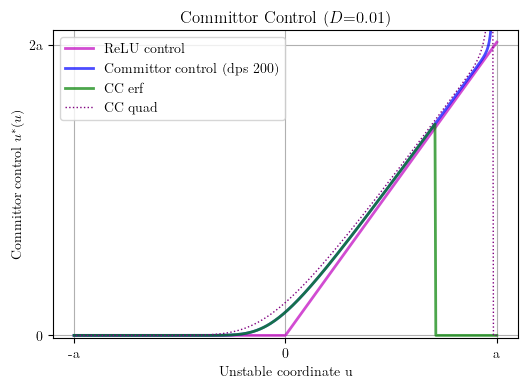

In [56]:
# Plot
plt.figure(figsize=(6,4))
plt.plot(-u_vals, u_relu, 'm', lw=2, label='ReLU control', alpha=0.7)
plt.plot(-u_vals, u_star_hp, 'b', lw=2, label=f'Committor control (dps {dps})', alpha=0.7) #decimal places of significant digits
plt.plot(-u_vals, u_star_erf, 'g', lw=2, label='CC erf', alpha=0.7)
#plt.plot(u_vals, u_star_erf_2, 'r--', lw=1, label='CC erf 2', alpha=0.7)
plt.plot(-u_vals, u_star_quad, ':', color='purple', lw=1, label='CC quad', alpha=1)

#plt.axhline(0, color='k', lw=0.8)
#plt.axvline(-a, color='r', ls='--', label='Absorbing A')
#plt.axvline(a, color='g', ls='--', label='Absorbing B')
plt.ylim([-0.02, 2*a + 0.1])
plt.xticks([-a, 0, a], ['-a', '0', 'a'])
plt.yticks([0, 2*a], ['0', '2a'])
plt.xlabel("Unstable coordinate u")
plt.ylabel("Committor control $u^*(u)$")
plt.title(f"Committor Control ($D$={D})")
plt.legend()
plt.grid(True)
plt.show()

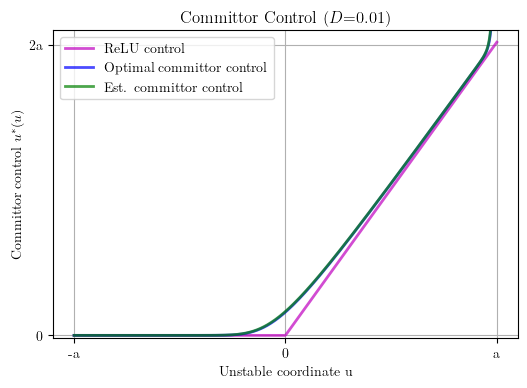

In [57]:
D_est = noise_strength_to_D(tracker.noise_strength, dt, dim)
r = tracker.lambda_history[-1] / (2*D_est)
u_star_hp_est = high_precision_control(u_vals, a=a, r=r, D=D_est, precision=dps)

plt.figure(figsize=(6,4))
plt.plot(-u_vals, u_relu, 'm', lw=2, label='ReLU control', alpha=0.7)
plt.plot(-u_vals, u_star_hp, 'b', lw=2, label=f'Optimal committor control', alpha=0.7) 
plt.plot(-u_vals, u_star_hp_est, 'g', lw=2, label=f'Est. committor control', alpha=0.7) 
plt.ylim([-0.02, 2*a + 0.1])
plt.xticks([-a, 0, a], ['-a', '0', 'a'])
plt.yticks([0, 2*a], ['0', '2a'])
plt.xlabel("Unstable coordinate u")
plt.ylabel("Committor control $u^*(u)$")
plt.title(f"Committor Control ($D$={D})")
plt.legend()
plt.grid(True)
plt.show()

In [15]:

# Standard SDE: dx = sqrt(2 D) dW
D_est = noise_strength_to_D(tracker.noise_strength, dt, dim, sde_convention="sqrt2D")

# Simulation convention: dx = noise_std * dW
D_est_sim = noise_strength_to_D(tracker.noise_strength, dt, dim, sde_convention="sqrtD")

print("D (sqrt2D convention):", D_est)
print("D (sqrtD convention):", D_est_sim)

D (sqrt2D convention): 0.01141560181176194
D (sqrtD convention): 0.02283120362352388


In [16]:
D_est

0.01141560181176194

In [17]:
def high_precision_feedback(x, l_unstable, lambda_u, D, x_fp=None, r_neigh=1.0):
    if x_fp is None:
        x_fp = np.zeros_like(x)
    dist = np.linalg.norm(x - x_fp)
    if dist > r_neigh:
        return np.zeros_like(x)
    
    u_scalar = -np.dot(l_unstable, x - x_fp)
    r = lambda_u / (2 * D)
    
    # call scalar version, not a list
    return -high_precision_control_scalar(u_scalar, a=0.5, r=r, D=D, precision=25) * l_unstable


def relu_feedback(x, l_unstable, lambda_u, D, x_fp=None, r_neigh=1.0):
    if x_fp is None:
        x_fp = np.zeros_like(x)

    dist = np.linalg.norm(x - x_fp)
    if dist > r_neigh:  # use r_neigh for neighborhood
        return np.zeros_like(x)

    proj = np.dot(l_unstable, x - x_fp)
    signal = 2 * lambda_u * proj
    return -np.maximum(signal, 0.0) * l_unstable

def relu_scalar(u_scalar, l_unstable, D):
    # Implement the ReLU control law
    return 2 * D * np.maximum(0, u_scalar) * l_unstable

In [18]:
def generate_initial_positions(n_traj, dim, seed=0):
    np.random.seed(seed)
    return [np.random.uniform(-0.5, 0.5, size=(dim,)) for _ in range(n_traj)]

def generate_noise(initial_positions, T, dim, noise_std, dt, seed=0):
    np.random.seed(seed)
    all_noise = []
    for _ in initial_positions:
        noise = np.random.randn(T, dim) * noise_std * np.sqrt(dt)
        all_noise.append(noise)
    return all_noise

def simulate_trajectory(x0, T, dim, dt, drift_func, noise, control_func=None):
    X = np.zeros((T, dim))
    X[0] = x0
    for t in range(1, T):
        dx = drift_func(t, X[t-1])
        u_t = control_func(X[t-1]) if control_func is not None else np.zeros(dim)
        X[t] = X[t-1] + dx*dt + u_t*dt + noise[t]
    return X

In [19]:
from functools import partial

def run_simulations(T, dim, dt, n_traj, drift_func, noise_std, 
                    l_unstable_real, lambda_u_real, D_real, tracker, controllers_to_run, r_neigh=0.5, seed=0):
    """
    Run multiple simulations with flexible control types using unified λ/D-based controllers.

    Parameters
    ----------
    T : int
        Number of timesteps.
    dim : int
        Dimension of the system.
    dt : float
        Timestep size.
    n_traj : int
        Number of trajectories.
    drift_func : callable
        Function f(t, x) computing the drift.
    noise_std : float
        Standard deviation of noise.
    lambda_u_real : float
        True unstable eigenvalue (for optimal control).
    D_real : float
        True diffusion constant (for optimal control).
    tracker : object
        Tracker object containing l_unstable, b_history, lambda_history, noise_history.
    controllers_to_run : dict
        key = label (str), value = control function or None for autonomous.
        Example:
        {
            "Autonomous": None,
            "Optimal": high_precision_feedback,
            "Committor (zero FP)": high_precision_feedback,
            "Committor (learned FP)": high_precision_feedback,
            "ReLU": relu_feedback
        }
    seed : int
        Random seed for reproducibility.

    Returns
    -------
    dict
        Keys = labels, values = list of trajectories (T x dim arrays)
    """
    # Generate initial positions and precompute noise
    np.random.seed(seed)
    initial_positions = [np.random.uniform(-0.5, 0.5, size=(dim,)) for _ in range(n_traj)]
    np.random.seed(seed)
    all_noise = [np.random.randn(T, dim) * noise_std * np.sqrt(dt) for _ in range(n_traj)]

    # True and estimated parameters
    b_est = tracker.b_history[-1]
    l_unstable_est = tracker.lu_history[-1]
    lambda_est = tracker.lambda_history[-1]
    D_est = tracker.noise_history[-1] / dim

    all_results = {}

    for label, control_func in controllers_to_run.items():
        trajectories = []
        for i, x0 in enumerate(initial_positions):
            noise = all_noise[i]

            # Wrap control function using partial
            if control_func is None:
                ctrl = lambda x: np.zeros_like(x)
            elif control_func == high_precision_feedback:
                # Determine which λ/D/x_fp to use
                if "Optimal" in label:
                    ctrl = partial(control_func, l_unstable=l_unstable_real,
                                   lambda_u=lambda_u_real, D=D_real, x_fp=None)
                elif "est. FP" in label:
                    ctrl = partial(control_func, l_unstable=l_unstable_est,
                                   lambda_u=lambda_est, D=D_est, x_fp=b_est, r_neigh=r_neigh)
                else:
                    ctrl = partial(control_func, l_unstable=l_unstable_est,
                                   lambda_u=lambda_est, D=D_est, x_fp=None, r_neigh=r_neigh)
            elif control_func == relu_feedback:
                if "Optimal" in label:
                    ctrl = partial(control_func, l_unstable=l_unstable_real,
                                   lambda_u=lambda_u_real, D=D_real, x_fp=None)
                elif "est. FP" in label:
                    ctrl = partial(control_func, l_unstable=l_unstable_est,
                                   lambda_u=lambda_est, D=D_est, x_fp=b_est, r_neigh=r_neigh)
                else:
                    ctrl = partial(control_func, l_unstable=l_unstable_est,
                               lambda_u=lambda_est, D=D_est,
                               x_fp=None, r_neigh=r_neigh)

            # Simulate trajectory
            X = simulate_trajectory(x0, T, dim, dt, drift_func, noise, control_func=ctrl)
            trajectories.append(X)

        all_results[label] = trajectories

    return all_results

In [20]:
def plot_trajectories(ax, trajectories_info, tracker, show_n=5, radius=0.5, title=None):
    """
    Efficient plotting of multiple trajectories on a single axis.
    
    trajectories_info: dict
        Keys are labels, values are tuples: (list of trajectories, color)
    """

    for label, (X_list, color) in trajectories_info.items():
        # Stack first show_n trajectories for vectorized plotting
        X_array = np.array(X_list[:show_n])  # shape: (n_traj, T, dim)
        # Plot all lines at once
        ax.plot(X_array[:,:,0].T, X_array[:,:,1].T, color=color, alpha=0.5, label=label)
        # Plot starting points
        ax.scatter(X_array[:,0,0], X_array[:,0,1], color='k', marker='x')

    # Reference objects
    ax.quiver(0, 0, tracker.l_unstable[0], tracker.l_unstable[1], color='darkblue', scale=3, label="$\hat{w}_u$")
    ax.scatter(tracker.b_history[-1,0], tracker.b_history[-1,1], color='k', s=50, zorder=100, label="Est. FP")

    # Neighborhood circle
    thetas = np.linspace(0, 2*np.pi, 100)
    ax.plot(radius*np.cos(thetas), radius*np.sin(thetas), 'k--', alpha=0.5)

    # ReLU reference line
    relu_line = [[-tracker.l_unstable[1], tracker.l_unstable[1]], 
                 [tracker.l_unstable[0], -tracker.l_unstable[0]]]
    ax.plot(relu_line[0], relu_line[1], 'k:', alpha=0.5)

    # Axes settings
    ax.set_xlim([-0.6, 0.6])
    ax.set_ylim([-0.6, 0.6])
    ax.set_xticks([-0.5, 0, 0.5])
    ax.set_yticks([-0.5, 0, 0.5])
    ax.set_xlabel("$x_1$", fontsize=16)
    ax.set_ylabel("$x_2$", fontsize=16)
    ax.grid(True)
    if title:
        ax.set_title(title)
    ax.legend()


In [21]:
n_traj = 1
dt = 0.01
T  = 1000
noise_std = 0.1
seed = 0
controllers_to_run = {
    "Autonomous": None,
    "Optimal": high_precision_feedback,
    "Committor": high_precision_feedback,
    "Committor (est. FP)": high_precision_feedback,
    "ReLU": relu_feedback
}

l_unstable_real=np.array([1, 0])
lambda_u_real = 1
D_real = D
all_results = run_simulations(T, dim, dt, n_traj, drift_func, noise_std,
                              l_unstable_real=l_unstable_real, lambda_u_real=lambda_u_real, D_real=D_real,
                             tracker=tracker, controllers_to_run=controllers_to_run, seed=0)


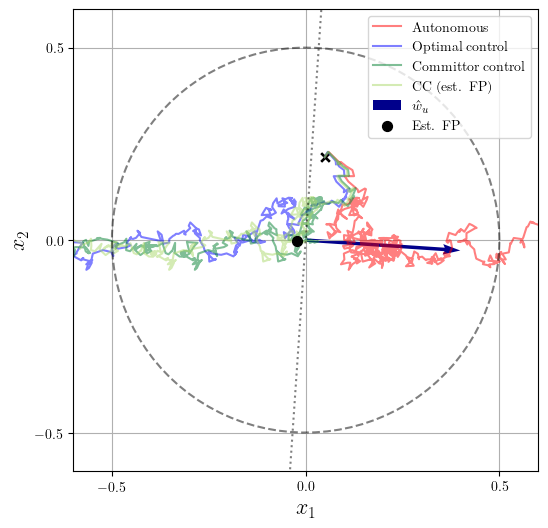

In [22]:
# Access trajectories like before:
all_X_uncontrolled = all_results["Autonomous"]
all_X_opt_ctrld = all_results["Optimal"]
all_X_relu_ctrld = all_results["ReLU"]
all_X_comm_ctrld = all_results["Committor"]
all_X_comm_ctrld_fp = all_results["Committor (est. FP)"]

trajectories_info = {
    "Autonomous": (all_X_uncontrolled, "red"),
    "Optimal control": (all_X_opt_ctrld, "blue"),
    #"ReLU control": (all_X_relu_ctrld, "orange"),
    "Committor control": (all_X_comm_ctrld, "#007f2f"),
    "CC (est. FP)": (all_X_comm_ctrld_fp, "#aad96a")
}

fig, ax = plt.subplots(figsize=(6,6))
plot_trajectories(ax, trajectories_info, tracker, show_n=5, title=None) #"Uncontrolled vs Optimal vs Committor control"
fig.savefig(f"figures/singletraj_comparison_rs{seed}.pdf", bbox_inches='tight')  
fig.savefig(f"figures/singletraj_comparison_rs{seed}.png", dpi=300, bbox_inches='tight')  
plt.show()


### Deterministic 

In [23]:
n_traj = 1
dt = 0.01
T  = 1000
noise_std = 0.
seed = 0
controllers_to_run = {
    "Autonomous": None,
    "ReLU": relu_feedback
}

lambda_u_real = 1
D_real = D
all_results = run_simulations(T, dim, dt, n_traj, drift_func, noise_std,
                              l_unstable_real=np.array([1, 0]), lambda_u_real=lambda_u_real, D_real=D_real,
                             tracker=tracker, controllers_to_run=controllers_to_run, seed=0)

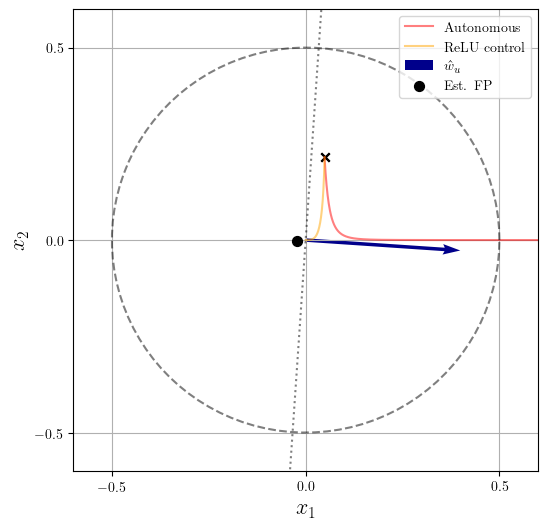

In [24]:
# Access trajectories like before:
all_X_uncontrolled = all_results["Autonomous"]
all_X_relu_ctrld = all_results["ReLU"]


trajectories_info = {
    "Autonomous": (all_X_uncontrolled, "red"),
    "ReLU control": (all_X_relu_ctrld, "orange"),
}

fig, ax = plt.subplots(figsize=(6,6))
plot_trajectories(ax, trajectories_info, tracker, show_n=5, title=None) 
#fig.savefig(f"figures/singletraj_comparison_rs{seed}.pdf", bbox_inches='tight')  
#fig.savefig(f"figures/singletraj_comparison_rs{seed}.png", dpi=300, bbox_inches='tight')  
plt.show()


# Empirical committor 

In [25]:
# Define sets A and B (in 2D)
def in_A(x, fp_loc=np.array([-1., 0.0]), radius=0.2):
    return np.linalg.norm(x - fp_loc) < radius

def in_B(x, fp_loc=np.array([1., 0.0]), radius=0.2):
    return np.linalg.norm(x - fp_loc) < radius



def empirical_committor_grid(sim_wrapper, n_traj=200, T=2000, dt=0.01, D=.0,
                             min_x=-0.5, max_x=0.5, num_points=10, seed=0, desc=""):
    """
    Compute empirical committor probability grid for a given simulation wrapper,
    including explicit noise strength D.

    Parameters
    ----------
    sim_wrapper : function
        Function with signature sim_wrapper(x0, T, dt, noise) -> trajectory (T x dim).
    n_traj : int
        Number of independent trajectories per grid point.
    T : int
        Number of timesteps per trajectory.
    dt : float
        Timestep size.
    D : float
        Noise strength (diffusion coefficient) to scale the stochastic term.
    min_x, max_x : float
        Grid boundaries.
    num_points : int
        Number of points along each dimension.
    desc : str
        Description for tqdm.

    Returns
    -------
    grid : np.ndarray
        1D grid points.
    q_grid : np.ndarray
        Empirical committor probabilities (num_points x num_points).
    """
    np.random.seed(seed)
    grid = np.linspace(min_x, max_x, num_points)
    q_grid = np.zeros((num_points, num_points))

    print(f"Calculating empirical committor for {desc}")
    for i, x1 in enumerate(tqdm(grid, desc="x1 grid")):
        for j, x2 in enumerate(grid):
            x0 = np.array([x1, x2])
            successes = 0

            # Pre-generate noise scaled by D
            noises = np.random.randn(n_traj, T, x0.size) * np.sqrt(2 * D * dt)

            for k in range(n_traj):
                X = sim_wrapper(x0.copy(), T, dt, noise=noises[k])

                # Early stopping when hitting A or B
                for t in range(T):
                    if in_A(X[t]):
                        break
                    if in_B(X[t]):
                        successes += 1
                        break

            q_grid[j, i] = successes / n_traj

    return grid, q_grid


def generic_simulation(x0, T, dt, control_func=None, noise=None):
    """
    Generic trajectory simulator including noise strength D in pre-generated noise.

    Parameters
    ----------
    x0 : np.ndarray
        Initial state.
    T : int
        Number of timesteps.
    dt : float
        Timestep size.
    control_func : callable or None
        Function control_func(x) -> u_t.
    noise : np.ndarray or None
        Pre-generated noise of shape (T, dim). If None, generate randomly.

    Returns
    -------
    X : np.ndarray
        Trajectory of shape (T, dim).
    """
    dim = x0.size
    X = np.zeros((T, dim))
    X[0] = x0

    if noise is None:
        raise ValueError("Noise array must be provided for scaled diffusion.")

    for t in range(1, T):
        dx = drift_func(t, X[t-1])
        u_t = control_func(X[t-1]) if control_func is not None else np.zeros(dim)
        X[t] = X[t-1] + dx*dt + u_t*dt + noise[t]

    return X


In [26]:
lambda_est = tracker.lambda_history[-1]
l_unstable_est = tracker.lu_history[-1]
D_est = 2*tracker.noise_history[-1] / dim
b_est = tracker.b_history[-1]

sim_uncontrolled = partial(generic_simulation, control_func=None)
sim_relu = partial(generic_simulation, control_func=partial(relu_feedback, l_unstable=l_unstable_est, lambda_u=lambda_est, D=D_est, x_fp=b_est, r_neigh=0.5))
sim_committor = partial(generic_simulation, control_func=partial(high_precision_feedback, l_unstable=l_unstable_est, lambda_u=lambda_est, D=D_est, x_fp=b_est, r_neigh=0.5))

In [27]:
grid, q_uncontrolled = empirical_committor_grid(sim_uncontrolled, D=2*D, n_traj=5, T=2000, dt=0.01, num_points=10, desc="Autonomous")
_, q_relu = empirical_committor_grid(sim_relu, D=2*D, n_traj=5, T=2000, dt=0.01, num_points=10, desc="ReLU control")
_, q_comm = empirical_committor_grid(sim_committor, D=2*D, n_traj=5, T=2000, dt=0.01, num_points=10, desc="Committor control")

Calculating empirical committor for Autonomous


x1 grid:   0%|          | 0/10 [00:00<?, ?it/s]

x1 grid:  80%|████████  | 8/10 [00:09<00:02,  1.20s/it]


KeyboardInterrupt: 

In [ ]:

sim_relu_opt = partial(generic_simulation, control_func=partial(relu_feedback, l_unstable=l_unstable_real, lambda_u=1., D=D, x_fp=np.array([0.,0.]), r_neigh=0.5))
_, q_relu_opt = empirical_committor_grid(sim_relu_opt, D=D, n_traj=5, T=2000, dt=0.01, num_points=10, desc="ReLU control")


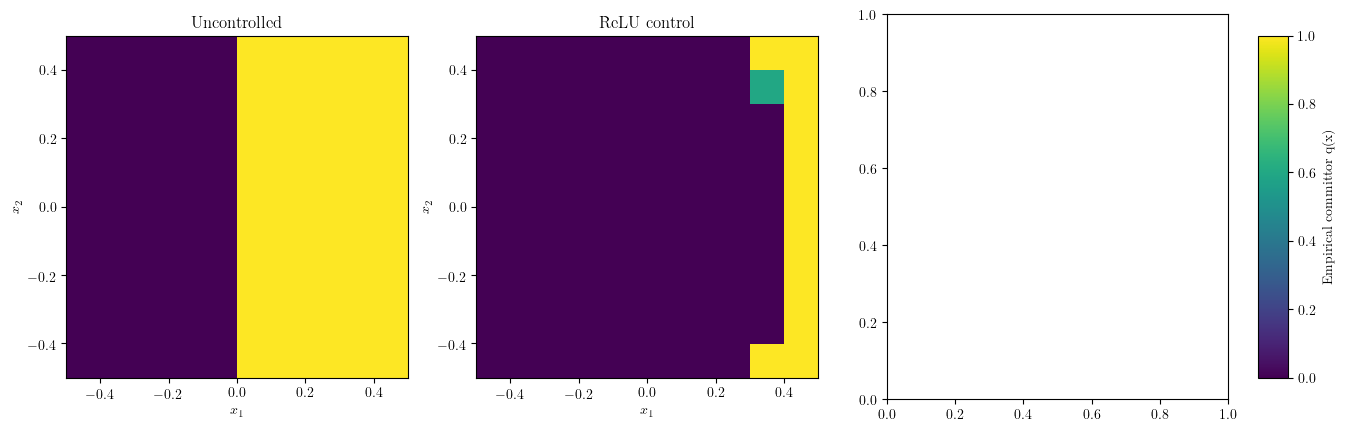

In [ ]:

# Plot results
fig, axs = plt.subplots(1, 3, figsize=(15, 5))
for ax, q, title in zip(
    axs,
    [q_uncontrolled, q_relu],
    ["Uncontrolled", "ReLU control"]
):
    im = ax.imshow(q, origin='lower', extent=[-0.5, 0.5, -0.5, 0.5],
                   vmin=0, vmax=1, cmap="viridis")
    ax.set_title(title)
    ax.set_xlabel("$x_1$")
    ax.set_ylabel("$x_2$")

# Get the bounding box of the subplots (they all have same y)
pos = axs[0].get_position()

# Place colorbar all the way to the right, matching subplot height
cbar_ax = fig.add_axes([0.92, pos.y0, 0.02, pos.height])
cbar = fig.colorbar(im, cax=cbar_ax, orientation='vertical')
cbar.set_label("Empirical committor q(x)")

plt.show()


In [ ]:
grid